In [9]:
import numpy as np
import matplotlib.pyplot as plt
import random
import sys
import os

sys.path.append(os.path.abspath(os.path.join('..')))

from utils.visualization import draw_field, draw_field_with_robot
from algorithms.particle_filter import *
from algorithms.Extended_Kalman_filter import *
from utils.Localization_metrics import *

## Настройка параметров модели фильтра частиц

In [10]:
particles_count = 5000  # hyperparam: particles count

# landmark coords
left_coord = Coord(-1, 5)
right_coord = Coord(1, 5)
lm = LandMark(left_coord, right_coord)

# standard deviation of noise for each dimension (x, y, theta)
system_noise = State(0.2, 0.2, 0.2)
sens_noise = np.array([0.05, 0.05, 0.05])  # camera noise

init_cov = np.array([
    system_noise.x ** 2,
    system_noise.y ** 2,
    system_noise.theta ** 2,
])

# initial state
state0 = State(0, 0, np.pi/2)

pf = ParticleFilter(
    particles_count,
    state0,
    lm,
    system_noise,
    sens_noise,
    is_adapt_resampl_enabled_=True,
    init_cov=init_cov,
)
local_metrics = LocalizationMetrics()


## Хождение робота на поле

In [11]:
from IPython.display import clear_output, display
import matplotlib.pyplot as plt

# steps_cnt = int(input())
# trajectory = [(pf.state.x, pf.state.y)]

# fig, ax = plt.subplots(figsize=(8, 10))
# draw_field_with_robot(pf.state, pf.particles, ax=ax)
# display(fig)

# for i in range(steps_cnt):
#     step = State(*map(float, input().split()))
#     est_state = pf.simulate(step)
    
#     local_metrics.update(pf.ideal_state, est_state)
#     trajectory.append((est_state.x, est_state.y))

#     draw_field_with_robot(est_state, pf.particles, ax=ax)

#     traj = np.array(trajectory)
#     ax.plot(traj[:, 0], traj[:, 1], color='red', linewidth=2)   # от стартовой точки
#     ax.plot(traj[:, 0], traj[:, 1], 'ko', markersize=3)          # узловые точки пути

#     clear_output(wait=True)
#     display(fig)

#     # print("estimated state: ", est_state)
#     # print("true state: ", pf.state)

# plt.close(fig)

# res = local_metrics.summary()

In [12]:
# # метрики оценки качества локализации
# res

## Эксперменты на оценку качества локализации

In [13]:
# рисуем круг
dt = 0.1
v = 0.6
R = 3

w = v / R
time_per_circle = (2 * np.pi * R) / v  # Время на один круг
steps_per_circle = int(time_per_circle / dt)

smooth_steps = []

# верхняя половина круга
for _ in range(steps_per_circle):
    smooth_steps.append(State(v * dt, 0, w * dt))

# нижняя половина круга
# for _ in range(steps_per_circle):
#     smooth_steps.append(State(v * dt, 0, -w * dt))

steps = smooth_steps

state0 = State(0.0, 0.0, 0.0)

print(f"Сгенерировано {len(steps)} шагов")

Сгенерировано 314 шагов


## Сравнение PF, EKF, камеры и одометрии


In [ ]:
# Единое сравнение на одном маршруте:
# PF и EKF получают одни и те же измерения, камера и одометрия — тот же ground truth.
# Ошибки считаются до true state, а не до ideal route.

import pandas as pd

pf = ParticleFilter(
    particles_count,
    state0,
    lm,
    system_noise,
    sens_noise,
    is_adapt_resampl_enabled_=True,
    init_cov=init_cov,
)
ekf = ExtendedKalmanFilter(
    state0,
    lm,
    system_noise,
    sens_noise,
    init_cov=init_cov,
)

# Проверка, что стартовые неопределённости согласованы
print("PF  initial std:", pf.particles.std(axis=0, ddof=1))
print("EKF initial std:", np.sqrt(np.diag(ekf.Sigma)))

methods = ["PF", "EKF", "Camera", "Odometry"]
method_labels = {
    "PF": "PF",
    "EKF": "EKF",
    "Camera": "Camera (raw)",
    "Odometry": "Odometry (no camera)",
}

metrics = {name: LocalizationMetrics() for name in methods}
trajectories = {name: [(state0.x, state0.y)] for name in methods}
ideal_trajectory = [(state0.x, state0.y)]
true_trajectory = [(state0.x, state0.y)]

for step_i in steps:
    # один общий ground truth
    pf.robot_move(step_i)
    z = pf.sensor_measurement()
    true_state = pf.state

    # PF update
    pf.particles_move(step_i)
    pf.weight_calc(z)
    pf_est = pf.estimate_state()

    if pf.is_adapt_resampl_enabled:
        if pf.effective_particles_calc() < pf.num_particles // 2:
            pf.resample()
    else:
        pf.resample()

    # EKF update по тому же измерению
    ekf.predict(step_i)
    ekf.update(*z)
    ekf_est = ekf.estimate_state()

    # Camera и Odometry на том же ground truth
    pf.camera_state = pf.camera_estimate_state(*z)
    pf.dead_reckoning_move(step_i)

    metrics["PF"].update(true_state, pf_est)
    metrics["EKF"].update(true_state, ekf_est)
    metrics["Camera"].update(true_state, pf.camera_state)
    metrics["Odometry"].update(true_state, pf.dead_reckoning_state)

    trajectories["PF"].append((pf_est.x, pf_est.y))
    trajectories["EKF"].append((ekf_est.x, ekf_est.y))
    trajectories["Camera"].append((pf.camera_state.x, pf.camera_state.y))
    trajectories["Odometry"].append(
        (pf.dead_reckoning_state.x, pf.dead_reckoning_state.y)
    )
    ideal_trajectory.append((pf.ideal_state.x, pf.ideal_state.y))
    true_trajectory.append((true_state.x, true_state.y))

summary = pd.DataFrame(
    {method_labels[name]: metrics[name].summary() for name in methods}
).T
summary = summary.rename(columns={
    "position_rmse": "Position RMSE, м",
    "position_mae": "Position MAE, м",
    "position_max": "Position max, м",
    "position_final": "Position final, м",
    "angle_rmse": "Angle RMSE, рад",
})
summary.index.name = "Метод"

summary.round(3)


PF  initial std: [0.19970801 0.20236594 0.19808755]
EKF initial std: [0.2 0.2 0.2]


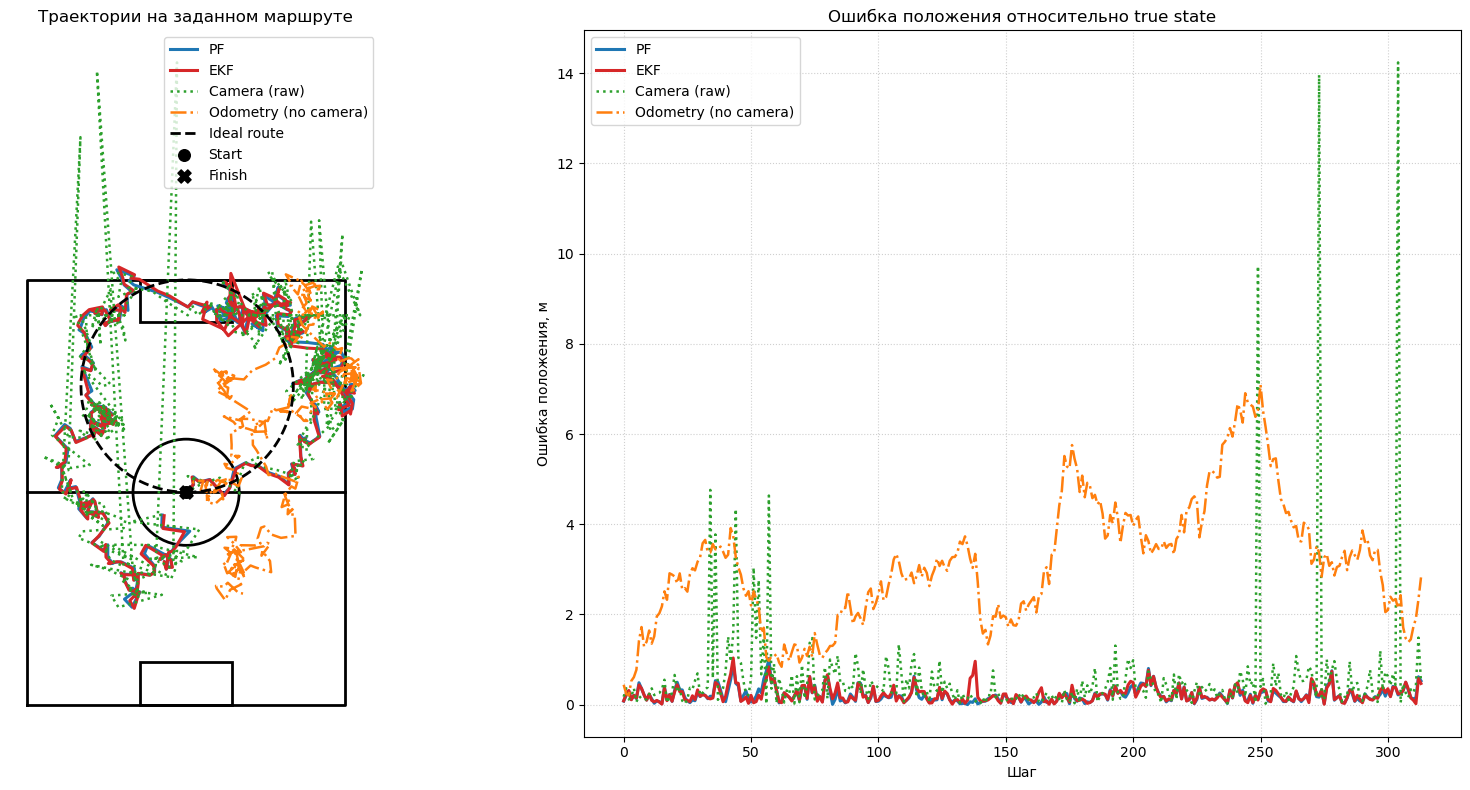

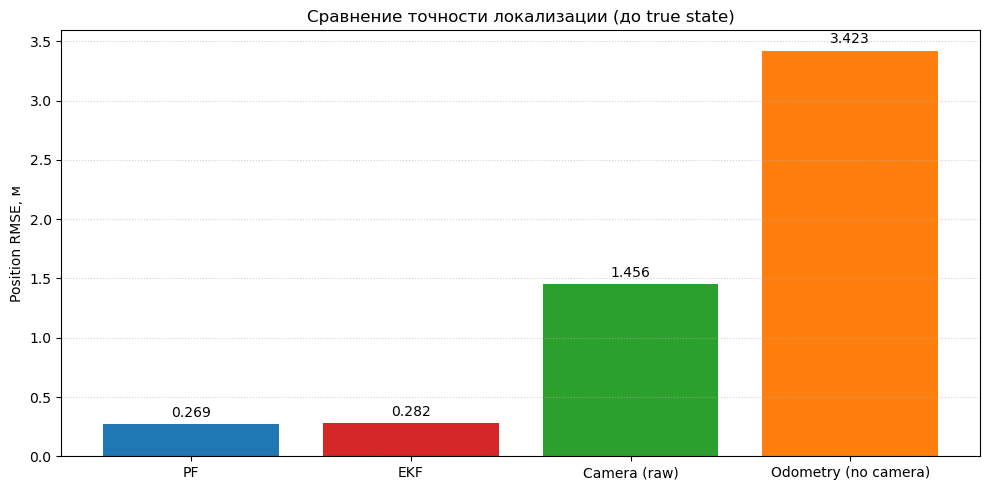

,"Position RMSE, м","Position MAE, м","Position max, м","Position final, м","Angle RMSE, рад"
Метод,,,,,
PF,0.269,0.213,1.024,0.528,0.098
EKF,0.282,0.226,1.035,0.470,0.102
Camera (raw),1.456,0.580,14.237,0.494,0.338
Odometry (no camera),3.423,3.126,7.093,2.821,1.497


In [7]:
method_styles = {
    "PF": dict(color="tab:blue", linewidth=2.2),
    "EKF": dict(color="tab:red", linewidth=2.2),
    "Camera": dict(color="tab:green", linewidth=1.8, linestyle=":"),
    "Odometry": dict(color="tab:orange", linewidth=1.8, linestyle="-."),
}

fig, (ax_route, ax_error) = plt.subplots(
    1, 2,
    figsize=(18, 8),
    gridspec_kw={"width_ratios": [1.15, 1]},
)

# Траектории на поле
draw_field(ax_route)

ideal_points = np.array(ideal_trajectory)
for name in methods:
    points = np.array(trajectories[name])
    ax_route.plot(
        points[:, 0],
        points[:, 1],
        label=method_labels[name],
        **method_styles[name],
    )

ax_route.plot(
    ideal_points[:, 0],
    ideal_points[:, 1],
    color="black",
    linestyle="--",
    linewidth=2,
    label="Ideal route",
)
ax_route.scatter(*ideal_points[0], color="black", s=70, zorder=8, label="Start")
ax_route.scatter(
    *ideal_points[-1], color="black", marker="X", s=90, zorder=8, label="Finish"
)

ax_route.set_title("Траектории на заданном маршруте")
ax_route.set_aspect("equal")
ax_route.axis("off")
ax_route.legend(loc="upper right")

# Ошибка положения по шагам
for name in methods:
    ax_error.plot(
        metrics[name].position_errors,
        label=method_labels[name],
        **method_styles[name],
    )

ax_error.set_title("Ошибка положения относительно true state")
ax_error.set_xlabel("Шаг")
ax_error.set_ylabel("Ошибка положения, м")
ax_error.grid(True, linestyle=":", alpha=0.6)
ax_error.legend()

plt.tight_layout()
plt.show()

# Итоговое сравнение точности
fig, ax = plt.subplots(figsize=(10, 5))

rmse = summary["Position RMSE, м"]
colors = [method_styles[name]["color"] for name in methods]
bars = ax.bar(
    [method_labels[name] for name in methods],
    [rmse[method_labels[name]] for name in methods],
    color=colors,
)
ax.bar_label(bars, fmt="%.3f", padding=3)

ax.set_ylabel("Position RMSE, м")
ax.set_title("Сравнение точности локализации (до true state)")
ax.grid(axis="y", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


### Усредняем PF, EKF, камеру и одометрию по seed'ам

In [8]:
import time

n = 20
particles_count = 3000

pf_rmses = []
ekf_rmses = []
camera_rmses = []
odom_rmses = []

pf_angle_rmses = []
ekf_angle_rmses = []

pf_times = []
ekf_times = []

for seed_i in range(n):
    # Seed задаёт общую симуляцию: одинаковые true-траектория и измерения
    np.random.seed(seed_i)
    random.seed(seed_i)

    pf = ParticleFilter(
        particles_count,
        state0,
        lm,
        system_noise,
        sens_noise,
        is_adapt_resampl_enabled_=True,
        init_cov=init_cov,
    )
    ekf = ExtendedKalmanFilter(
        state0,
        lm,
        system_noise,
        sens_noise,
        init_cov=init_cov,
    )

    metrics = {name: LocalizationMetrics() for name in methods}

    time_pf = 0.0
    time_ekf = 0.0

    for step_i in steps:
        # один общий ground truth и одно измерение
        pf.robot_move(step_i)
        z = pf.sensor_measurement()
        true_state = pf.state

        # PF
        t0 = time.perf_counter()
        pf.particles_move(step_i)
        pf.weight_calc(z)
        pf_est = pf.estimate_state()

        if pf.is_adapt_resampl_enabled:
            if pf.effective_particles_calc() < pf.num_particles // 2:
                pf.resample()
        else:
            pf.resample()
        time_pf += time.perf_counter() - t0

        # EKF по тому же измерению
        t0 = time.perf_counter()
        ekf.predict(step_i)
        ekf.update(*z)
        ekf_est = ekf.estimate_state()
        time_ekf += time.perf_counter() - t0

        # Camera и Odometry на том же ground truth
        pf.camera_state = pf.camera_estimate_state(*z)
        pf.dead_reckoning_move(step_i)

        metrics["PF"].update(true_state, pf_est)
        metrics["EKF"].update(true_state, ekf_est)
        metrics["Camera"].update(true_state, pf.camera_state)
        metrics["Odometry"].update(true_state, pf.dead_reckoning_state)

    pf_summary = metrics["PF"].summary()
    ekf_summary = metrics["EKF"].summary()
    camera_summary = metrics["Camera"].summary()
    odom_summary = metrics["Odometry"].summary()

    pf_rmses.append(pf_summary["position_rmse"])
    ekf_rmses.append(ekf_summary["position_rmse"])
    camera_rmses.append(camera_summary["position_rmse"])
    odom_rmses.append(odom_summary["position_rmse"])

    pf_angle_rmses.append(pf_summary["angle_rmse"])
    ekf_angle_rmses.append(ekf_summary["angle_rmse"])

    pf_times.append(time_pf)
    ekf_times.append(time_ekf)

    print(
        f"seed {seed_i}: PF={pf_rmses[-1]:.4f}, "
        f"EKF={ekf_rmses[-1]:.4f}, "
        f"Camera={camera_rmses[-1]:.4f}, "
        f"Odometry={odom_rmses[-1]:.4f}"
    )

pf_rmses = np.array(pf_rmses)
ekf_rmses = np.array(ekf_rmses)
camera_rmses = np.array(camera_rmses)
odom_rmses = np.array(odom_rmses)

print(f"\nPF       mean RMSE: {pf_rmses.mean():.4f} ± {pf_rmses.std(ddof=1):.4f}")
print(f"EKF      mean RMSE: {ekf_rmses.mean():.4f} ± {ekf_rmses.std(ddof=1):.4f}")
print(f"Camera   mean RMSE: {camera_rmses.mean():.4f} ± {camera_rmses.std(ddof=1):.4f}")
print(f"Odometry mean RMSE: {odom_rmses.mean():.4f} ± {odom_rmses.std(ddof=1):.4f}")
print(f"PF  mean time: {np.mean(pf_times):.4f} s")
print(f"EKF mean time: {np.mean(ekf_times):.4f} s")

seed_summary = pd.DataFrame({
    "seed": np.arange(n),
    "PF": pf_rmses,
    "EKF": ekf_rmses,
    "Camera": camera_rmses,
    "Odometry": odom_rmses,
})
seed_summary.round(4)


seed 0: PF=0.7165, EKF=0.7406, Camera=2.5220, Odometry=10.7824
seed 1: PF=0.3261, EKF=0.3257, Camera=5.2816, Odometry=9.6288


KeyboardInterrupt: 

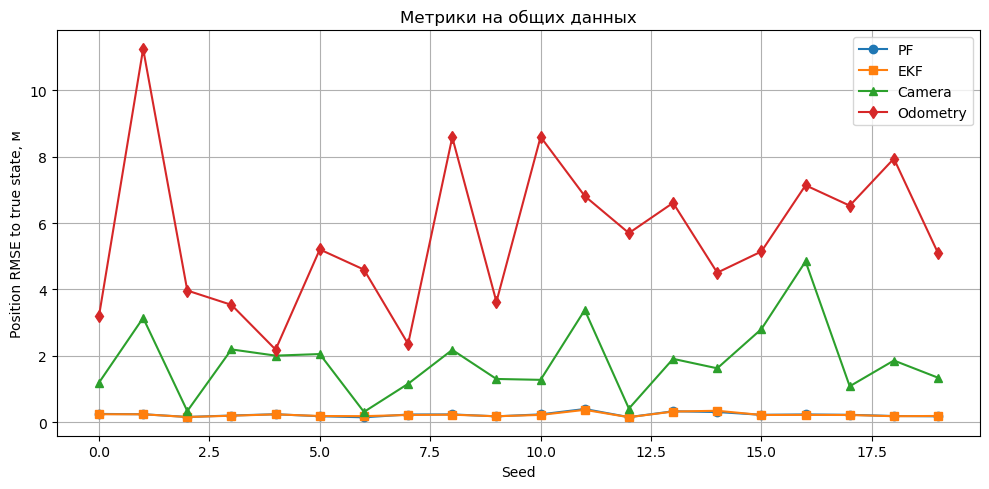

PF  mean RMSE: 0.2314
EKF mean RMSE: 0.2296
Camera mean RMSE: 1.8235
Odometry mean RMSE: 5.6280


In [9]:
fig, ax_rmse = plt.subplots(figsize=(10, 5))

ax_rmse.plot(np.arange(n), pf_rmses, 'o-', label="PF")
ax_rmse.plot(np.arange(n), ekf_rmses, 's-', label="EKF")
ax_rmse.plot(np.arange(n), camera_rmses, '^-', label="Camera")
ax_rmse.plot(np.arange(n), odom_rmses, 'd-', label="Odometry")

ax_rmse.set_xlabel("Seed")
ax_rmse.set_ylabel("Position RMSE to true state, м")
ax_rmse.set_title("Метрики на общих данных")
ax_rmse.legend()
ax_rmse.grid()

plt.tight_layout()
plt.show()

print(f"PF  mean RMSE: {pf_rmses.mean():.4f}")
print(f"EKF mean RMSE: {ekf_rmses.mean():.4f}")
print(f"Camera mean RMSE: {camera_rmses.mean():.4f}")
print(f"Odometry mean RMSE: {odom_rmses.mean():.4f}")


### Сценарий: kidnapping и глобальная релокализация

In [10]:
import pandas as pd

kidnap_step = 100
kidnap_state = State(-3, 3, -np.pi / 2)
kidnap_particles = 3000
kidnap_seeds = [0, 1, 2]
max_steps_after_kidnap = 200

def run_kidnap(seed_i):
    np.random.seed(seed_i)
    random.seed(seed_i)

    pf = ParticleFilter(
        kidnap_particles,
        state0,
        lm,
        system_noise,
        sens_noise,
        is_adapt_resampl_enabled_=True,
        init_cov=init_cov,
    )
    ekf = ExtendedKalmanFilter(
        state0,
        lm,
        system_noise,
        sens_noise,
        init_cov=init_cov,
    )

    pf_metrics = LocalizationMetrics()
    ekf_metrics = LocalizationMetrics()

    for step_i, step in enumerate(steps[:kidnap_step + max_steps_after_kidnap]):
        if step_i == kidnap_step:
            # Робота перенесли в другую точку поля
            pf.state = State(kidnap_state.x, kidnap_state.y, kidnap_state.theta)
            pf.ideal_state = State(kidnap_state.x, kidnap_state.y, kidnap_state.theta)

            # PF: глобальная релокализация
            pf.randomize_particles()

            # EKF: релокализация недоступна, продолжаем от старой оценки

        # Общий ground truth и общее измерение
        pf.robot_move(step)
        z = pf.sensor_measurement()
        true_state = pf.state

        # PF
        pf.particles_move(step)
        pf.weight_calc(z)
        pf_est = pf.estimate_state()

        if pf.effective_particles_calc() < pf.num_particles // 2:
            pf.resample()

        # EKF по тому же измерению
        ekf.predict(step)
        ekf.update(*z)
        ekf_est = ekf.estimate_state()

        pf_metrics.update(true_state, pf_est)
        ekf_metrics.update(true_state, ekf_est)

    return (
        np.array(pf_metrics.position_errors),
        np.array(ekf_metrics.position_errors),
    )

pf_kidnap_errors = []
ekf_kidnap_errors = []

for seed_i in kidnap_seeds:
    pf_err, ekf_err = run_kidnap(seed_i)
    pf_kidnap_errors.append(pf_err)
    ekf_kidnap_errors.append(ekf_err)

pf_kidnap_errors = np.array(pf_kidnap_errors)
ekf_kidnap_errors = np.array(ekf_kidnap_errors)

pf_kidnap_mean = pf_kidnap_errors.mean(axis=0)
ekf_kidnap_mean = ekf_kidnap_errors.mean(axis=0)

def recovery_time(errors, start_step, threshold=0.2):
    for i in range(start_step, len(errors)):
        if np.all(errors[i:] < threshold):
            return i - start_step
    return None

pf_recovery = [recovery_time(e, kidnap_step) for e in pf_kidnap_errors]
ekf_recovery = [recovery_time(e, kidnap_step) for e in ekf_kidnap_errors]

pf_post_rmse = np.sqrt(np.mean(pf_kidnap_errors[:, kidnap_step:] ** 2, axis=1))
ekf_post_rmse = np.sqrt(np.mean(ekf_kidnap_errors[:, kidnap_step:] ** 2, axis=1))

kidnap_summary = pd.DataFrame({
    "seed": kidnap_seeds,
    "PF post-kidnap RMSE, м": pf_post_rmse,
    "EKF post-kidnap RMSE, м": ekf_post_rmse,
    "PF recovery, шагов": pf_recovery,
    "EKF recovery, шагов": ekf_recovery,
})
kidnap_summary.round(3)


,seed,"PF post-kidnap RMSE, м","EKF post-kidnap RMSE, м","PF recovery, шагов","EKF recovery, шагов"
0,0,0.274,0.852,NaN,NaN
1,1,0.230,0.399,196.0,196.0
2,2,0.217,0.337,193.0,NaN


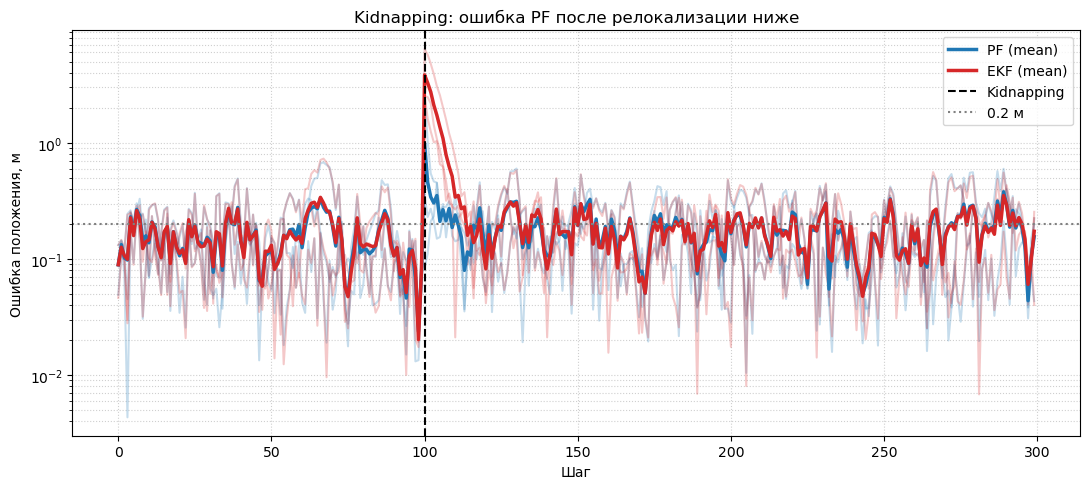

In [11]:
fig, ax = plt.subplots(figsize=(11, 5))

for i in range(len(kidnap_seeds)):
    ax.plot(pf_kidnap_errors[i], color="tab:blue", alpha=0.25)
    ax.plot(ekf_kidnap_errors[i], color="tab:red", alpha=0.25)

ax.plot(pf_kidnap_mean, color="tab:blue", linewidth=2.5, label="PF (mean)")
ax.plot(ekf_kidnap_mean, color="tab:red", linewidth=2.5, label="EKF (mean)")

ax.axvline(kidnap_step, color="black", linestyle="--", label="Kidnapping")
ax.axhline(0.2, color="gray", linestyle=":", label="0.2 м")

ax.set_yscale("log")
ax.set_xlabel("Шаг")
ax.set_ylabel("Ошибка положения, м")
ax.set_title("Kidnapping: ошибка PF после релокализации ниже")
ax.grid(True, which="both", linestyle=":", alpha=0.6)
ax.legend()

plt.tight_layout()
plt.show()


### Оценка сходимости PF после релокализации

In [ ]:
def generate_simulation(seed=42):
    np.random.seed(seed)
    random.seed(seed)

    sim = ParticleFilter(
        particles_count,
        state0,
        lm,
        system_noise,
        sens_noise,
        is_adapt_resampl_enabled_=True,
        init_cov=init_cov,
    )

    true_states = []
    measurements = []

    for step in steps:
        sim.robot_move(step)
        true_states.append(State(sim.state.x, sim.state.y, sim.state.theta))
        measurements.append(sim.sensor_measurement())

    return true_states, measurements


def run_experiment(true_states, measurements, relocalization=False, seed=42):
    np.random.seed(seed)
    random.seed(seed)

    pf = ParticleFilter(
        particles_count,
        state0,
        lm,
        system_noise,
        sens_noise,
        is_adapt_resampl_enabled_=True,
        init_cov=init_cov,
    )

    metrics = LocalizationMetrics()

    for i, (step, true_state, z) in enumerate(
        zip(steps, true_states, measurements)
    ):
        if relocalization and (i in relocalization_steps):
            pf.randomize_particles()

        pf.particles_move(step)
        pf.weight_calc(z)
        est_state = pf.estimate_state()

        if pf.is_adapt_resampl_enabled:
            if pf.effective_particles_calc() < pf.num_particles // 2:
                pf.resample()
        else:
            pf.resample()

        metrics.update(true_state, est_state)

    return metrics


In [ ]:
relocalization_steps = {100, 200, 300}

# Одна и та же истинная траектория и одни и те же измерения для обоих запусков
true_states, measurements = generate_simulation(seed=42)

metrics_without = run_experiment(
    true_states, measurements, relocalization=False, seed=42
)
metrics_with = run_experiment(
    true_states, measurements, relocalization=True, seed=42
)

plt.figure(figsize=(10, 5))

plt.plot(
    metrics_without.position_errors,
    marker="o",
    label="Без релокализации"
)

plt.plot(
    metrics_with.position_errors,
    marker="o",
    label="С релокализацией"
)

for i, reloc_step in enumerate(sorted(relocalization_steps)):
    plt.axvline(
        reloc_step,
        linestyle="--",
        color="gray",
        alpha=0.6,
        label="Релокализация" if i == 0 else None,
    )

plt.xlabel("Шаг")
plt.ylabel("Ошибка позиции")
plt.title("PF на одинаковых данных: с релокализацией и без")
plt.grid()
plt.legend()
plt.show()


In [14]:
print("Без релокализации:")
print(metrics_without.summary())

print("\nС релокализацией:")
print(metrics_with.summary())

Без релокализации:
{'position_rmse': np.float64(0.24858364952049455), 'position_mae': np.float64(0.185621642748307), 'position_max': np.float64(0.9992228662543247), 'position_final': np.float64(0.04069179430240934), 'angle_rmse': np.float64(0.09368040259327172)}

С релокализацией:
{'position_rmse': np.float64(0.27578750778891997), 'position_mae': np.float64(0.22024966255419484), 'position_max': np.float64(0.8555126110242401), 'position_final': np.float64(0.5451993330510341), 'angle_rmse': np.float64(0.07225426257115222)}


### Влияние числа частиц на качество локализации  

In [ ]:
import time
import random
import numpy as np
import pandas as pd


particle_counts = [5, 10, 50, 100, 200, 400, 800, 1000, 1500, 2000, 3000, 4000]
seeds = [41, 42, 43, 44, 45]

results = []
runs = []

for n_particles in particle_counts:

    print(f"n_particles = {n_particles}")

    position_rmse = []
    angle_rmse = []
    all_squared_errors = [] 
    time_total = []

    for seed in seeds:
        np.random.seed(seed)
        random.seed(seed)

        pf = ParticleFilter(
            n_particles,
            state0,
            lm,
            system_noise,
            sens_noise,
            is_adapt_resampl_enabled_=True,
            init_cov=init_cov,
        )

        metrics = LocalizationMetrics()

        start_time = time.perf_counter()

        for step in steps:
            est_state = pf.simulate(step)
            metrics.update(pf.state, est_state)

        elapsed = time.perf_counter() - start_time

        summary = metrics.summary()

        position_rmse.append(summary["position_rmse"])
        angle_rmse.append(summary["angle_rmse"])
        time_total.append(elapsed)

        raw_errors = metrics.get_raw_errors()
        all_squared_errors.extend(raw_errors ** 2)

        runs.append({
            "particles": n_particles,
            "seed": seed,
            "position_rmse": summary["position_rmse"],
            "angle_rmse": summary["angle_rmse"],
            "time_total": elapsed,
            "time_per_step": elapsed / len(steps)
        })

    true_pooled_rmse = np.sqrt(np.mean(all_squared_errors))

    results.append({
        "particles": n_particles,

        "position_rmse_mean": true_pooled_rmse,

        # "position_rmse_mean": np.mean(position_rmse),
        "position_rmse_std": np.std(position_rmse, ddof=1),

        "angle_rmse_mean": np.mean(angle_rmse),
        "angle_rmse_std": np.std(angle_rmse, ddof=1),

        "time_total_mean": np.mean(time_total),
        "time_total_std": np.std(time_total, ddof=1),

        "time_per_step": np.mean(time_total) / len(steps),
        "time_per_step_std": np.std(time_total, ddof=1) / len(steps)
    })


results_df = pd.DataFrame(results)
runs_df = pd.DataFrame(runs)

results_df

n_particles = 5
n_particles = 10
n_particles = 50
n_particles = 100
n_particles = 200
n_particles = 400
n_particles = 800
n_particles = 1000
n_particles = 1500
n_particles = 2000
n_particles = 3000
n_particles = 4000


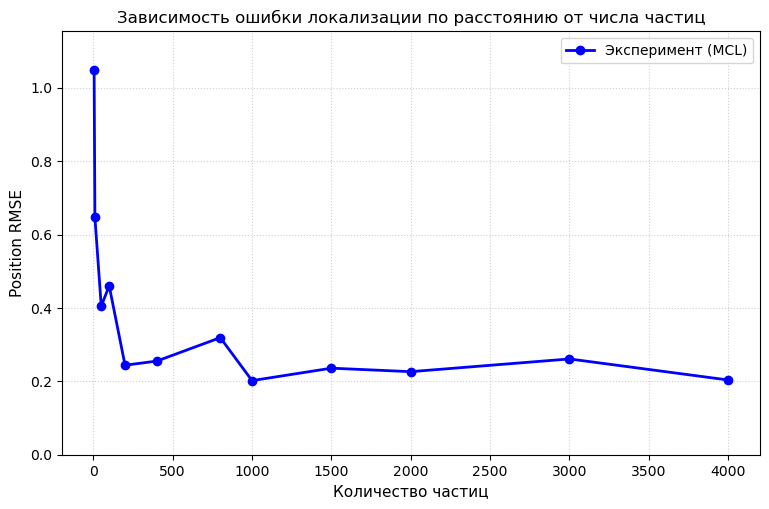

In [16]:
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

rmse_data = results_df['position_rmse_mean']

plt.figure(figsize=(9, 5.5), dpi=100)
plt.plot(particle_counts, rmse_data, 'o-', color='b', label='Эксперимент (MCL)', linewidth=2)

plt.ylim(0, 1.1 * rmse_data.max()) 

plt.title('Зависимость ошибки локализации по расстоянию от числа частиц', fontsize=12)
plt.xlabel('Количество частиц', fontsize=11)
plt.ylabel('Position RMSE', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()


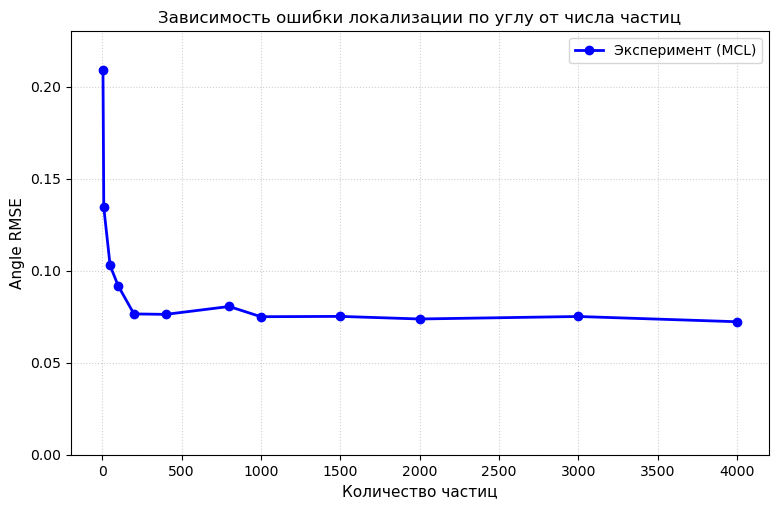

In [17]:
angle_data = results_df['angle_rmse_mean']
plt.figure(figsize=(9, 5.5), dpi=100)
plt.plot(particle_counts, angle_data, 'o-', color='b', label='Эксперимент (MCL)', linewidth=2)

plt.ylim(0, 1.1 * angle_data.max()) 

plt.title('Зависимость ошибки локализации по углу от числа частиц', fontsize=12)
plt.xlabel('Количество частиц', fontsize=11)
plt.ylabel('Angle RMSE', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

На подумать: можно в torch найти аналогичные фильтры (KF, EKF, PF) для сравнения: [TorchFilters](https://stanford-iprl-lab.github.io/torchfilter/api/torchfilter/filters/)